In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('cleaned_data.csv')

In [3]:
df.head()

,academic_unit,genai_familiarity,llm_familiarity,prompt_engineering_familiarity,adequate_genai_training,need_more_genai_training,understand_genai_classroom_use,students_need_more_genai_training,university_genai_discussion_channels,genai_training_unnecessary,...,concern_categories,instructor_gender,instructor_age,years_of_teaching_experience,highest_education_level,hispanic_latino_ethnicity,instructor_race,other_race_description,undergraduate_graduate_teaching,residential_online_teaching
0,Arts and Sciences,Very familiar,Very familiar,Very familiar,Agree,Disagree,Agree,Disagree,Agree,Neutral,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Business,Somewhat familiar,Somewhat familiar,Somewhat unfamiliar,Agree,Disagree,Disagree,Disagree,Agree,Disagree,...,NaN,Man,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Business,Very familiar,Very familiar,Neutral,Agree,Agree,Agree,Agree,Agree,Agree,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arts and Sciences,Not at all familiar,Not at all familiar,Not at all familiar,Strongly disagree,Strongly disagree,Strongly disagree,Strongly agree,Strongly agree,Strongly disagree,...,NaN,Man,NaN,NaN,PhD/Doctoral degree,No,NaN,NaN,NaN,NaN
4,Arts and Sciences,Very familiar,Very familiar,Somewhat unfamiliar,Strongly disagree,Neutral,Agree,Agree,Agree,Strongly disagree,...,NaN,Man,NaN,15.0,PhD/Doctoral degree,Yes,NaN,NaN,Undergraduate,Residential


### AI Familiarity by Academic Unit

In [4]:
df["academic_unit"].value_counts(dropna=False)

academic_unit
Arts and Sciences    114
Business              24
Education             13
Law                   12
Marine Science         8
Not reported           7
Name: count, dtype: int64

In [5]:
df[["academic_unit", "genai_familiarity"]].head(10)

,academic_unit,genai_familiarity
0,Arts and Sciences,Very familiar
1,Business,Somewhat familiar
2,Business,Very familiar
3,Arts and Sciences,Not at all familiar
4,Arts and Sciences,Very familiar
5,Arts and Sciences,Very familiar
6,Business,Somewhat familiar
7,Arts and Sciences,Very familiar
8,Arts and Sciences,Very familiar
9,Arts and Sciences,Very familiar


In [6]:
df["genai_familiarity"].value_counts(dropna=False)

genai_familiarity
Somewhat familiar      94
Very familiar          53
Somewhat unfamiliar    12
Neutral                10
Not at all familiar     9
Name: count, dtype: int64

In [7]:
df["genai_familiarity"].value_counts(normalize=True) * 100

genai_familiarity
Somewhat familiar      52.808989
Very familiar          29.775281
Somewhat unfamiliar     6.741573
Neutral                 5.617978
Not at all familiar     5.056180
Name: proportion, dtype: float64

In [8]:
familiarity_counts = pd.crosstab(
    df["academic_unit"],
    df["genai_familiarity"]
)

familiarity_counts

genai_familiarity,Neutral,Not at all familiar,Somewhat familiar,Somewhat unfamiliar,Very familiar
academic_unit,,,,,
Arts and Sciences,8,7,63,7,29
Business,1,0,11,0,12
Education,0,1,7,2,3
Law,0,0,6,1,5
Marine Science,1,1,3,2,1
Not reported,0,0,4,0,3


In [9]:
familiarity_pct = pd.crosstab(
    df["academic_unit"],
    df["genai_familiarity"],
    normalize="index"
) * 100

familiarity_pct.round(1)

genai_familiarity,Neutral,Not at all familiar,Somewhat familiar,Somewhat unfamiliar,Very familiar
academic_unit,,,,,
Arts and Sciences,7.0,6.1,55.3,6.1,25.4
Business,4.2,0.0,45.8,0.0,50.0
Education,0.0,7.7,53.8,15.4,23.1
Law,0.0,0.0,50.0,8.3,41.7
Marine Science,12.5,12.5,37.5,25.0,12.5
Not reported,0.0,0.0,57.1,0.0,42.9


In [10]:
familiarity_order = [
    "Not at all familiar",
    "Somewhat unfamiliar",
    "Neutral",
    "Somewhat familiar",
    "Very familiar"
]

familiarity_pct = familiarity_pct.reindex(columns=familiarity_order)

familiarity_pct.round(1)

genai_familiarity,Not at all familiar,Somewhat unfamiliar,Neutral,Somewhat familiar,Very familiar
academic_unit,,,,,
Arts and Sciences,6.1,6.1,7.0,55.3,25.4
Business,0.0,0.0,4.2,45.8,50.0
Education,7.7,15.4,0.0,53.8,23.1
Law,0.0,8.3,0.0,50.0,41.7
Marine Science,12.5,25.0,12.5,37.5,12.5
Not reported,0.0,0.0,0.0,57.1,42.9


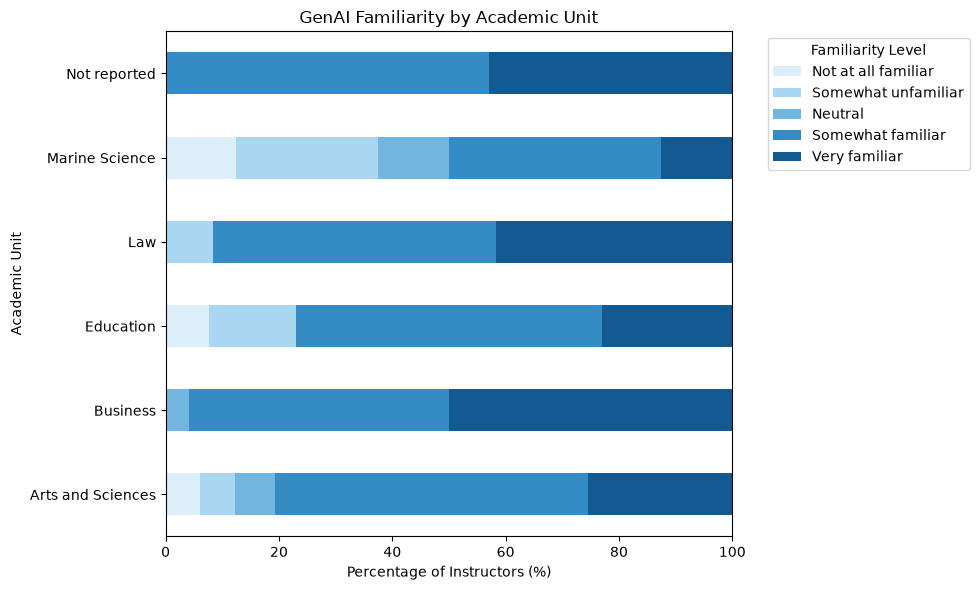

In [11]:
familiarity_pct.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    color=["#DCEEF9", "#A9D6F0", "#72B6DF", "#358CC5", "#125A91"]
)

plt.title("GenAI Familiarity by Academic Unit")
plt.xlabel("Percentage of Instructors (%)")
plt.ylabel("Academic Unit")
plt.xlim(0, 100)

plt.legend(
    title="Familiarity Level",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Interpret the Results

In [12]:
# Calculate the percentage of instructors with high GenAI familiarity
high_familiarity = (
    familiarity_pct["Somewhat familiar"] +
    familiarity_pct["Very familiar"]
)
high_familiarity.sort_values(ascending=False).round(1)

academic_unit
Not reported         100.0
Business              95.8
Law                   91.7
Arts and Sciences     80.7
Education             76.9
Marine Science        50.0
dtype: float64

In [13]:
# Count valid familiarity responses in each academic unit
valid_responses = familiarity_counts.sum(axis=1)

valid_responses

academic_unit
Arts and Sciences    114
Business              24
Education             13
Law                   12
Marine Science         8
Not reported           7
dtype: int64

In [14]:
# Create a summary table and rank academic units by high familiarity
summary = pd.DataFrame({
    "Valid Responses": valid_responses,
    "High Familiarity (%)": high_familiarity
})

summary.sort_values(
    "High Familiarity (%)",
    ascending=False
).round(1)

,Valid Responses,High Familiarity (%)
academic_unit,,
Not reported,7,100.0
Business,24,95.8
Law,12,91.7
Arts and Sciences,114,80.7
Education,13,76.9
Marine Science,8,50.0


### Concern Analysis by Academic Unit

In [15]:
df[["academic_unit", "concern_categories"]].head(10)

,academic_unit,concern_categories
0,Arts and Sciences,NaN
1,Business,NaN
2,Business,NaN
3,Arts and Sciences,NaN
4,Arts and Sciences,NaN
5,Arts and Sciences,NaN
6,Business,"Academic Integrity, Critical Thinking & Learni..."
7,Arts and Sciences,"AI Literacy & Training, Ethics & Bias, Environ..."
8,Arts and Sciences,Critical Thinking & Learning
9,Arts and Sciences,Critical Thinking & Learning


In [16]:
df["concern_categories"].value_counts(dropna=False)

concern_categories
NaN                                                                                                             51
Critical Thinking & Learning                                                                                    13
Policies & Adoption                                                                                             12
Critical Thinking & Learning, Writing & Creativity                                                               8
Critical Thinking & Learning, Accuracy & Misinformation                                                          7
Academic Integrity                                                                                               7
No Concerns                                                                                                      7
Academic Integrity, Critical Thinking & Learning, Writing & Creativity                                           4
Accuracy & Misinformation                                    

In [17]:
# Create an empty list for individual concerns
concern_list = []

# Separate and collect each concern
for response in df["concern_categories"].dropna():
    for concern in response.split(","):
        concern = concern.strip()

        if concern not in ["No Concerns", "No Experience", "Unclear / Not Specified"]:
            concern_list.append(concern)

In [18]:
# Count and rank individual concerns
concern_counts = pd.Series(concern_list).value_counts()

concern_counts

Critical Thinking & Learning        50
Academic Integrity                  29
AI Literacy & Training              22
Writing & Creativity                22
Accuracy & Misinformation           22
Policies & Adoption                 21
Teaching & Assessment Challenges    19
Ethics & Bias                        9
Environmental & Social Impact        5
Equity & Accessibility               3
Name: count, dtype: int64

In [19]:
# Select the required columns and remove missing values
concern_by_unit = df[["academic_unit", "concern_categories"]].dropna().copy()

# Split multiple concerns into lists
concern_by_unit["concern_categories"] = concern_by_unit["concern_categories"].str.split(",")

# Create a separate row for each concern
concern_by_unit = concern_by_unit.explode("concern_categories", ignore_index=True)

# Remove extra spaces
concern_by_unit["concern_categories"] = concern_by_unit["concern_categories"].str.strip()

In [20]:
# Remove responses that are not actual concerns
valid_concerns = concern_by_unit[
    ~concern_by_unit["concern_categories"].isin(
        ["No Concerns", "No Experience", "Unclear / Not Specified"]
    )
]

# Count each concern by academic unit
concern_table = pd.crosstab(
    valid_concerns["concern_categories"],
    valid_concerns["academic_unit"]
)

concern_table

academic_unit,Arts and Sciences,Business,Education,Law,Marine Science,Not reported
concern_categories,,,,,,
AI Literacy & Training,13,2,3,3,1,0
Academic Integrity,23,2,2,0,0,2
Accuracy & Misinformation,15,3,1,1,2,0
Critical Thinking & Learning,30,8,3,2,3,4
Environmental & Social Impact,4,1,0,0,0,0
Equity & Accessibility,2,0,0,1,0,0
Ethics & Bias,5,0,1,3,0,0
Policies & Adoption,13,5,1,1,1,0
Teaching & Assessment Challenges,13,2,2,1,0,1


In [21]:
# Count instructors with valid concern responses in each academic unit
valid_answers = df.dropna(subset=["academic_unit", "concern_categories"])

valid_answers = valid_answers[
    ~valid_answers["concern_categories"].isin(
        ["No Concerns", "No Experience", "Unclear / Not Specified"]
    )
]

unit_counts = valid_answers["academic_unit"].value_counts()

# Convert concern counts to percentages
concern_pct = concern_table.div(unit_counts, axis=1) * 100

concern_pct.round(1)

academic_unit,Arts and Sciences,Business,Education,Law,Marine Science,Not reported
concern_categories,,,,,,
AI Literacy & Training,17.6,12.5,33.3,60.0,20.0,0.0
Academic Integrity,31.1,12.5,22.2,0.0,0.0,40.0
Accuracy & Misinformation,20.3,18.8,11.1,20.0,40.0,0.0
Critical Thinking & Learning,40.5,50.0,33.3,40.0,60.0,80.0
Environmental & Social Impact,5.4,6.2,0.0,0.0,0.0,0.0
Equity & Accessibility,2.7,0.0,0.0,20.0,0.0,0.0
Ethics & Bias,6.8,0.0,11.1,60.0,0.0,0.0
Policies & Adoption,17.6,31.2,11.1,20.0,20.0,0.0
Teaching & Assessment Challenges,17.6,12.5,22.2,20.0,0.0,20.0


In [22]:
# Create an empty table for heatmap labels
labels = pd.DataFrame(
    index=concern_pct.index,
    columns=concern_pct.columns
)

# Add percentage and count to each label
for concern in concern_pct.index:
    for unit in concern_pct.columns:
        pct = concern_pct.loc[concern, unit]
        count = concern_table.loc[concern, unit]
        total = unit_counts[unit]

        labels.loc[concern, unit] = f"{pct:.1f}%\n({count}/{total})"

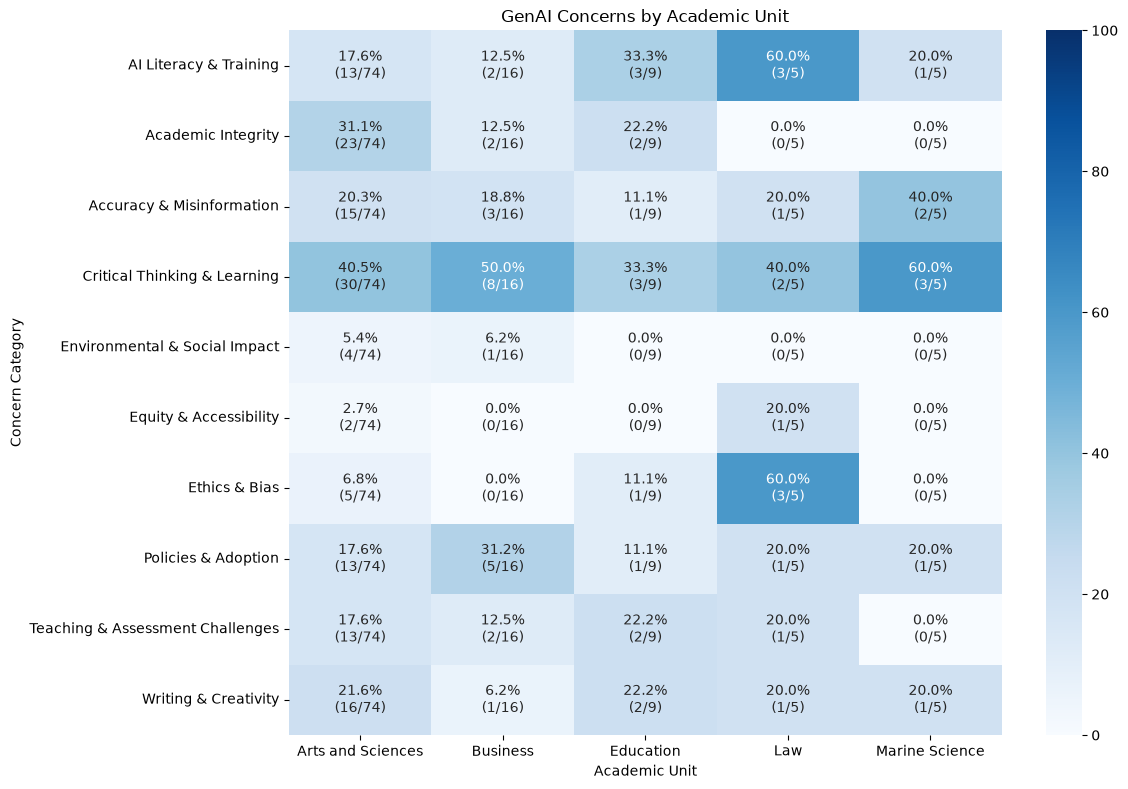

In [23]:
# Remove the unspecified academic unit from the chart
plot_data = concern_pct.drop(columns="Not reported", errors="ignore")
plot_labels = labels[plot_data.columns]

# Plot percentages with counts
plt.figure(figsize=(12, 8))

sns.heatmap(
    plot_data,
    annot=plot_labels,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("GenAI Concerns by Academic Unit")
plt.xlabel("Academic Unit")
plt.ylabel("Concern Category")

plt.tight_layout()
plt.show()